# InceptionResNetV2 — Replicare Nawaz (toate cele 5 tier-uri)

**Strict Nawaz:**
- Architecture: InceptionResNetV2 + Dense(1024) + BN + Dropout + Dense(256) + BN + Dropout + Dense(7)
- Total params: 56,179,943 (match Table 4)
- Loss: sparse_categorical_crossentropy + class_weight (sklearn balanced)
- Optimizer: Adam, LR=1e-3
- Augmentation: flip + rotation +/- 20° + zoom +/- 10%
- Base trainable
- 30 epochs cu EarlyStopping(patience=10) pe val_accuracy
- ReduceLROnPlateau pe val_loss

## 1. Setup

In [16]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted


In [17]:
import os
import json
import time
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from scipy.ndimage import rotate as scipy_rotate
from sklearn.metrics import ( classification_report, confusion_matrix, roc_auc_score, precision_recall_fscore_support )

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f'TF: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')
print(f'Seed: {SEED}')

TF: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seed: 42


In [18]:
DRIVE_BASE = Path('/content/drive/MyDrive/Thesis')
PIPELINE_DIR = DRIVE_BASE / 'pipeline_outputs'

TFRECORDS_DIR = PIPELINE_DIR / 'step4_tfrecords'   # val/, test/, tier5/
STEP2_DIR = PIPELINE_DIR / 'step2'                 # tier{N}_train.csv
OUTPUT_DIR = DRIVE_BASE / 'experiments' / 'inceptionresnetv2_naive'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Hyperparameters (strict Nawaz)
IMG_SIZE = 224
NUM_CLASSES = 7
BATCH_SIZE = 32
EPOCHS = 30
LEARNING_RATE = 1e-3
DENSE1_UNITS = 1024
DENSE2_UNITS = 256
DROPOUT_RATE = 0.3
ROTATION_MAX_DEG = 20
ZOOM_RANGE = 0.1

PAPER_TRAINABLE_PARAMS = 1_840_647
TIERS_TO_RUN = [1, 2, 3, 4, 5]
IDX_TO_LABEL = {0: 'akiec', 1: 'bcc', 2: 'bkl', 3: 'df', 4: 'mel', 5: 'nv', 6: 'vasc'}
CLASS_NAMES = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]

print(f'TFRecords dir:  {TFRECORDS_DIR.exists()} {TFRECORDS_DIR}')
print(f'Step2 dir:      {STEP2_DIR.exists()} {STEP2_DIR}')
print(f'Output dir:     {OUTPUT_DIR}')
print(f'Tiers to run:   {TIERS_TO_RUN}')

for split in ['val', 'test', 'tier5']:
    d = TFRECORDS_DIR / split
    if d.exists():
        shards = sorted(d.glob('*.tfrecord'))
        print(f'  {split}: {len(shards)} shard-uri')
    else:
        print(f'  [WARNING] {split}/ nu există!')

TFRecords dir:  True /content/drive/MyDrive/Thesis/pipeline_outputs/step4_tfrecords
Step2 dir:      True /content/drive/MyDrive/Thesis/pipeline_outputs/step2
Output dir:     /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive
Tiers to run:   [1, 2, 3, 4, 5]
  val: 3 shard-uri
  test: 3 shard-uri
  tier5: 21 shard-uri


## 2. Data pipeline



In [19]:
FEATURE_DESC = {
    'image_id':    tf.io.FixedLenFeature([], tf.string),
    'label':       tf.io.FixedLenFeature([], tf.int64),
    'lesion_id':   tf.io.FixedLenFeature([], tf.string),
    'source':      tf.io.FixedLenFeature([], tf.string),
    'image_bytes': tf.io.FixedLenFeature([], tf.string),
}


def parse_example(example_proto):
    return tf.io.parse_single_example(example_proto, FEATURE_DESC)


def decode_image(parsed):
    img = tf.io.decode_jpeg(parsed['image_bytes'], channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0   # [0, 1]
    return img, parsed['label'], parsed['lesion_id']


def get_split_files(split_name):
    pattern = str(TFRECORDS_DIR / split_name / '*.tfrecord')
    files = sorted(tf.io.gfile.glob(pattern))
    if not files:
        raise FileNotFoundError(f'No TFRecords found for split: {split_name}')
    return files


TRAIN_FILES = get_split_files('tier5')
VAL_FILES = get_split_files('val')
TEST_FILES = get_split_files('test')

print(f'Train pool (tier5): {len(TRAIN_FILES)} shards')
print(f'Val:                {len(VAL_FILES)} shards')
print(f'Test:               {len(TEST_FILES)} shards')

Train pool (tier5): 21 shards
Val:                3 shards
Test:               3 shards


In [20]:
def get_tier_lesion_ids(tier):

    if tier == 5:
        return None
    csv_path = STEP2_DIR / f'tier{tier}_train.csv'
    df = pd.read_csv(csv_path)
    return set(df['lesion_id'].astype(str).tolist())

def make_lesion_filter(allowed_ids):

    keys = tf.constant(sorted(list(allowed_ids)), dtype=tf.string)
    values = tf.ones(len(allowed_ids), dtype=tf.int32)
    table = tf.lookup.StaticHashTable(
        tf.lookup.KeyValueTensorInitializer(keys, values),
        default_value=0,
    )
    return table

for t in TIERS_TO_RUN:
    ids = get_tier_lesion_ids(t)
    if ids is None:
        print(f'Tier {t}: no filter (full tier5)')
    else:
        print(f'Tier {t}: {len(ids):,} lesion_id-uri')

Tier 1: 5,987 lesion_id-uri
Tier 2: 7,276 lesion_id-uri
Tier 3: 8,565 lesion_id-uri
Tier 4: 9,855 lesion_id-uri
Tier 5: no filter (full tier5)


In [21]:
def _random_rotate_np(image_np, max_deg):
    angle = np.random.uniform(-max_deg, max_deg)
    return scipy_rotate( image_np, angle, reshape=False, order=1, mode='reflect' ).astype(np.float32)


def augment_image(image, rotation_deg=ROTATION_MAX_DEG, zoom=ZOOM_RANGE):

    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = tf.numpy_function(
        func=lambda x: _random_rotate_np(x, rotation_deg),
        inp=[image], Tout=tf.float32,
    )
    image.set_shape([None, None, 3])

    zoom_factor = tf.random.uniform([], 1.0 - zoom, 1.0 + zoom)
    new_size = tf.cast(tf.cast(IMG_SIZE, tf.float32) / zoom_factor, tf.int32)
    image = tf.image.resize(image, [new_size, new_size])
    image = tf.image.resize_with_crop_or_pad(image, IMG_SIZE, IMG_SIZE)
    image = tf.clip_by_value(image, 0.0, 1.0)
    return image

def preprocess_for_model(img_01):
    """Input: float32 [0,1]. Apply InceptionResNetV2 preprocessing."""
    img_255 = img_01 * 255.0
    return tf.keras.applications.inception_resnet_v2.preprocess_input(img_255)

print('Augmentation + preprocessing definite')

Augmentation + preprocessing definite


In [22]:
# ─── Dataset builders ───

def build_train_ds(tier):
    """Train dataset cu .repeat() — filter pe lesion_id pentru tier1-4."""
    allowed_ids = get_tier_lesion_ids(tier)

    ds = tf.data.TFRecordDataset(TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)

    # Filter pe lesion_id pentru tier1-4
    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter(lambda img, lbl, lid: tf.equal(table.lookup(lid), 1))

    # Drop lesion_id
    ds = ds.map(lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE)

    # CRITICAL: .repeat() ÎNAINTE de shuffle ca să nu rămânem fără date la fitting
    ds = ds.repeat()
    ds = ds.shuffle(buffer_size=2000, seed=SEED, reshuffle_each_iteration=True)

    # Augment + preprocess
    ds = ds.map(
        lambda img, lbl: (augment_image(img), lbl),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    ds = ds.map(
        lambda img, lbl: (preprocess_for_model(img), lbl),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    ds = ds.batch(BATCH_SIZE, drop_remainder=True)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


def build_eval_ds(files):
    """Val/test dataset — fără shuffle, fără repeat, fără augment."""
    ds = tf.data.TFRecordDataset(files, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(
        lambda img, lbl: (preprocess_for_model(img), lbl),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


print('Dataset builders definite')

Dataset builders definite


In [23]:
# ─── Numărăm sample-urile per tier (pentru class_weight + steps_per_epoch) ───

def count_tier_samples(tier):
    """Numără sample-uri și calculează distribuția pe clase pentru un tier."""
    allowed_ids = get_tier_lesion_ids(tier)

    ds = tf.data.TFRecordDataset(TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)

    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter(lambda x: tf.equal(table.lookup(x['lesion_id']), 1))

    counter = Counter()
    for ex in ds:
        counter[int(ex['label'].numpy())] += 1
    return dict(counter)


TIER_DISTRIBUTIONS = {}
print('Counting samples per tier (asta poate dura ~1-2 min):')
for t in TIERS_TO_RUN:
    dist = count_tier_samples(t)
    TIER_DISTRIBUTIONS[t] = dist
    total = sum(dist.values())
    print(f'  Tier {t}: {total:>6,} samples — {{{", ".join(f"{IDX_TO_LABEL[k]}: {v}" for k, v in sorted(dist.items()))}}}')

# Val/test sample counts
val_count = sum(1 for _ in tf.data.TFRecordDataset(VAL_FILES))
test_count = sum(1 for _ in tf.data.TFRecordDataset(TEST_FILES))
print(f'\nVal:  {val_count:,} samples')
print(f'Test: {test_count:,} samples')

Counting samples per tier (asta poate dura ~1-2 min):
  Tier 1:  8,042 samples — {akiec: 268, bcc: 396, bkl: 888, df: 93, mel: 910, nv: 5378, vasc: 109}
  Tier 2: 10,996 samples — {akiec: 502, bcc: 929, bkl: 1177, df: 118, mel: 1600, nv: 6536, vasc: 134}
  Tier 3: 14,061 samples — {akiec: 720, bcc: 1495, bkl: 1504, df: 138, mel: 2296, nv: 7750, vasc: 158}
  Tier 4: 17,300 samples — {akiec: 946, bcc: 2077, bkl: 1836, df: 164, mel: 3062, nv: 9022, vasc: 193}
  Tier 5: 20,299 samples — {akiec: 1192, bcc: 2661, bkl: 2128, df: 184, mel: 3628, nv: 10297, vasc: 209}

Val:  2,519 samples
Test: 2,513 samples


In [24]:
# ─── Class weights pentru fiecare tier (sklearn balanced) ───

def compute_class_weights(distribution):
    """sklearn 'balanced': total / (n_classes * count_per_class)."""
    total = sum(distribution.values())
    return {k: total / (NUM_CLASSES * v) for k, v in distribution.items()}


TIER_CLASS_WEIGHTS = {}
print('Class weights per tier:')
for t in TIERS_TO_RUN:
    cw = compute_class_weights(TIER_DISTRIBUTIONS[t])
    TIER_CLASS_WEIGHTS[t] = cw
    cw_str = ', '.join(f'{IDX_TO_LABEL[k]}: {v:.2f}' for k, v in sorted(cw.items()))
    print(f'  Tier {t}: {cw_str}')

Class weights per tier:
  Tier 1: akiec: 4.29, bcc: 2.90, bkl: 1.29, df: 12.35, mel: 1.26, nv: 0.21, vasc: 10.54
  Tier 2: akiec: 3.13, bcc: 1.69, bkl: 1.33, df: 13.31, mel: 0.98, nv: 0.24, vasc: 11.72
  Tier 3: akiec: 2.79, bcc: 1.34, bkl: 1.34, df: 14.56, mel: 0.87, nv: 0.26, vasc: 12.71
  Tier 4: akiec: 2.61, bcc: 1.19, bkl: 1.35, df: 15.07, mel: 0.81, nv: 0.27, vasc: 12.81
  Tier 5: akiec: 2.43, bcc: 1.09, bkl: 1.36, df: 15.76, mel: 0.80, nv: 0.28, vasc: 13.87


## 3. Model (strict Nawaz Table 5)

Architecture:
```
Input(224, 224, 3)
  → InceptionResNetV2 (5,919,312)
  → GlobalAveragePooling2D
  → Dense(1024, relu) (1,311,744)
  → BatchNormalization (4,096)
  → Dropout(0.3)
  → Dense(256, relu) (262,400)
  → BatchNormalization (1,024)
  → Dropout(0.3)
  → Dense(7, softmax) (1,799)
Total: 56,179,943
Trainable: 1,840,647
```

In [25]:
def build_inceptionresnetv2():
    """Strict Nawaz Table 5 — Total 56,179,943 / Trainable 1,840,647 (base frozen)."""
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    base = tf.keras.applications.InceptionResNetV2( include_top=False, weights='imagenet', input_shape=(IMG_SIZE, IMG_SIZE, 3) )
    base.trainable = False
    for layer in base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)

    x = tf.keras.layers.Dense(DENSE1_UNITS, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(DROPOUT_RATE)(x)
    x = tf.keras.layers.Dense(DENSE2_UNITS, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(DROPOUT_RATE)(x)

    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    model = tf.keras.Model(inputs, outputs, name='InceptionResNetV2')

    total = model.count_params()
    trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
    print(f'  Total params:     {total:>12,}')
    print(f'  Trainable params: {trainable:>12,}  (BN-uri din bază înghețate)')

    return model

_test_model = build_inceptionresnetv2()
del _test_model
tf.keras.backend.clear_session()

  Total params:       56,179,943
  Trainable params:    1,840,647  (BN-uri din bază înghețate)
  Paper Table 4:       1,840,647  (cu BN trainable)


## 4. Training utilities

In [26]:
def get_callbacks(tier_dir):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(tier_dir / 'best.keras'),
            monitor='val_accuracy', mode='max',
            save_best_only=True, verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', mode='max',
            patience=10, restore_best_weights=True, verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5,
            patience=3, min_lr=1e-7, verbose=1,
        ),
        tf.keras.callbacks.CSVLogger(
            filename=str(tier_dir / 'history.csv'), append=False,
        ),
    ]


print('Callbacks definite')

Callbacks definite


In [27]:
def evaluate_model(model, ds, label='test'):
    """Evaluate cu accuracy, precision, recall, F1, AUC, confusion matrix."""

    print(f'Evaluating on {label}...')
    y_true, y_pred, y_proba = [], [], []
    for imgs, labels in ds:
        preds = model.predict(imgs, verbose=0)
        y_proba.extend(preds)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_proba = np.array(y_proba)

    acc = float(np.mean(y_true == y_pred))
    prec, rec, f1, _ = precision_recall_fscore_support( y_true, y_pred, average='weighted', zero_division=0 )
    macro_f1 = precision_recall_fscore_support( y_true, y_pred, average='macro', zero_division=0 )[2]
    try:
        auc = float(roc_auc_score(y_true, y_proba, multi_class='ovr', average='weighted'))
    except Exception:
        auc = float('nan')

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    report = classification_report( y_true, y_pred, target_names=CLASS_NAMES, zero_division=0 )

    print(f'  Accuracy:    {acc*100:.2f}%')
    print(f'  Precision:   {prec:.4f}')
    print(f'  Recall:      {rec:.4f}')
    print(f'  Weighted F1: {f1:.4f}')
    print(f'  Macro F1:    {macro_f1:.4f}')
    print(f'  AUC (ovr):   {auc:.4f}')

    return {
        'accuracy': acc,
        'precision': float(prec),
        'recall': float(rec),
        'weighted_f1': float(f1),
        'macro_f1': float(macro_f1),
        'auc': auc,
        'confusion_matrix': cm.tolist(),
        'classification_report': report,
    }

In [28]:
def plot_results(history, cm, tier, save_path):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    axes[0].plot(history.history['accuracy'], label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Val')
    axes[0].set_title(f'Tier {tier} — Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history.history['loss'], label='Train')
    axes[1].plot(history.history['val_loss'], label='Val')
    axes[1].set_title(f'Tier {tier} — Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False )
    axes[2].set_title(f'Tier {tier} — Confusion Matrix (test)')
    axes[2].set_xlabel('Predicted')
    axes[2].set_ylabel('True')

    plt.tight_layout()
    plt.savefig(save_path, dpi=120, bbox_inches='tight')
    plt.show()

In [29]:
def train_tier(tier):
    """Antrenează un tier. Returnează dict cu rezultatele."""

    tier_dir = OUTPUT_DIR / f'tier{tier}'
    tier_dir.mkdir(parents=True, exist_ok=True)

    results_path = tier_dir / 'results.json'
    if results_path.exists():
        print(f'\n   Tier {tier} already done, loading...')
        with open(results_path) as f:
            return json.load(f)

    print(f'\n{"#"*70}')
    print(f'# TIER {tier}')
    print(f'#   Output: {tier_dir}')
    print(f'#   Train samples: {sum(TIER_DISTRIBUTIONS[tier].values()):,}')
    print(f'#   LR={LEARNING_RATE}, batch={BATCH_SIZE}, epochs={EPOCHS}')
    print(f'{"#"*70}')

    start = time.time()
    tf.random.set_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)

    train_ds = build_train_ds(tier)
    val_ds = build_eval_ds(VAL_FILES)
    test_ds = build_eval_ds(TEST_FILES)

    train_samples = sum(TIER_DISTRIBUTIONS[tier].values())
    steps_per_epoch = max(1, (train_samples // BATCH_SIZE) - 1)
    print(f'  Steps per epoch: {steps_per_epoch}')

    model = build_inceptionresnetv2()
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )

    history = model.fit(
        train_ds,
        epochs=EPOCHS,
        steps_per_epoch=steps_per_epoch,
        validation_data=val_ds,
        class_weight=TIER_CLASS_WEIGHTS[tier],
        callbacks=get_callbacks(tier_dir),
        verbose=1,
    )

    val_metrics = evaluate_model(model, val_ds, label=f'tier{tier}_val')
    test_metrics = evaluate_model(model, test_ds, label=f'tier{tier}_test')
    plot_results( history, np.array(test_metrics['confusion_matrix']), tier, save_path=tier_dir / 'plots.png' )
    elapsed_min = (time.time() - start) / 60

    results = {
        'tier': tier,
        'train_samples': train_samples,
        'epochs_run': len(history.history['loss']),
        'time_minutes': elapsed_min,
        'val': val_metrics,
        'test': test_metrics,
        'history': {k: [float(x) for x in v] for k, v in history.history.items()},
    }

    with open(results_path, 'w') as f:
        json.dump(results, f, indent=2, default=str)
    model.save(tier_dir / 'final.keras')

    print(f'\n  Tier {tier} done in {elapsed_min:.1f} min')
    print(f'  Test accuracy: {test_metrics["accuracy"]*100:.2f}%')

    del model, train_ds, val_ds, test_ds
    tf.keras.backend.clear_session()
    import gc
    gc.collect()

    return results

## 5. Run all tiers


######################################################################
# TIER 1
#   Output: /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier1
#   Train samples: 8,042
#   LR=0.001, batch=32, epochs=30
######################################################################
  Steps per epoch: 250
  Total params:       56,179,943
  Trainable params:    1,840,647  (BN-uri din bază înghețate)
  Paper Table 4:       1,840,647  (cu BN trainable)
Epoch 1/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.2695 - loss: 2.1671
Epoch 1: val_accuracy improved from None to 0.43351, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier1/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier1/best.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 75s 177ms/step - accuracy: 0.3224 - loss: 1.9231 - val_accuracy: 0.4335 - val_loss: 1.8687 - learning_rate: 0.0010
Epoch 2/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.4228 - loss: 1.5521
Epoch 2: val_accuracy did not improve from 0.43351
250/250 ━━━━━━━━━━━━━━━━━━━━ 24s 96ms/step - accuracy: 0.4433 - loss: 1.5036 - val_accuracy: 0.3847 - val_loss: 2.0637 - learning_rate: 0.0010
Epoch 3/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.4643 - loss: 1.4549
Epoch 3: val_accuracy did not improve from 0.43351
250/250 ━━━━━━━━━━━━━━━━━━━━ 22s 88ms/step - accuracy: 0.4794 - loss: 1.4102 - val_accuracy: 0.3783 - val_loss: 1.8634 - learning_rate: 0.0010
Epoch 4/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.5052 - loss: 1.2235
Epoch 4: val_accuracy improved from 0.43351 to 0.46169, saving model to /content/drive/My

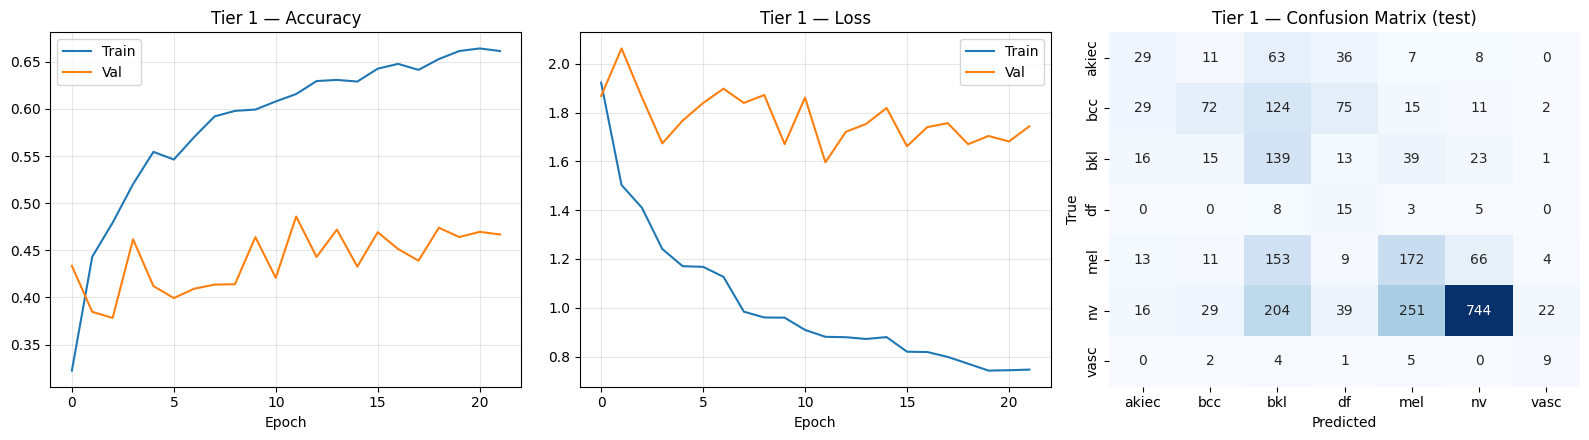


✓ Tier 1 done in 9.7 min
  Test accuracy: 46.96%

######################################################################
# TIER 2
#   Output: /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier2
#   Train samples: 10,996
#   LR=0.001, batch=32, epochs=30
######################################################################
  Steps per epoch: 342
  Total params:       56,179,943
  Trainable params:    1,840,647  (BN-uri din bază înghețate)
  Paper Table 4:       1,840,647  (cu BN trainable)
Epoch 1/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.3191 - loss: 1.9952
Epoch 1: val_accuracy improved from None to 0.40929, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier2/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier2/best.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 80s 146ms/step - accuracy: 0.3751 - loss: 1.8493 - val_accuracy: 0.4093 - val_loss: 1.9643 - learning_rate: 0.0010
Epoch 2/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.4489 - loss: 1.4771
Epoch 2: val_accuracy did not improve from 0.40929
342/342 ━━━━━━━━━━━━━━━━━━━━ 27s 79ms/step - accuracy: 0.4496 - loss: 1.5336 - val_accuracy: 0.3763 - val_loss: 1.7457 - learning_rate: 0.0010
Epoch 3/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.4891 - loss: 1.3177
Epoch 3: val_accuracy did not improve from 0.40929
342/342 ━━━━━━━━━━━━━━━━━━━━ 27s 79ms/step - accuracy: 0.4929 - loss: 1.3538 - val_accuracy: 0.3573 - val_loss: 2.0247 - learning_rate: 0.0010
Epoch 4/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5033 - loss: 1.2827
Epoch 4: val_accuracy improved from 0.40929 to 0.42834, saving model to /content/drive/My

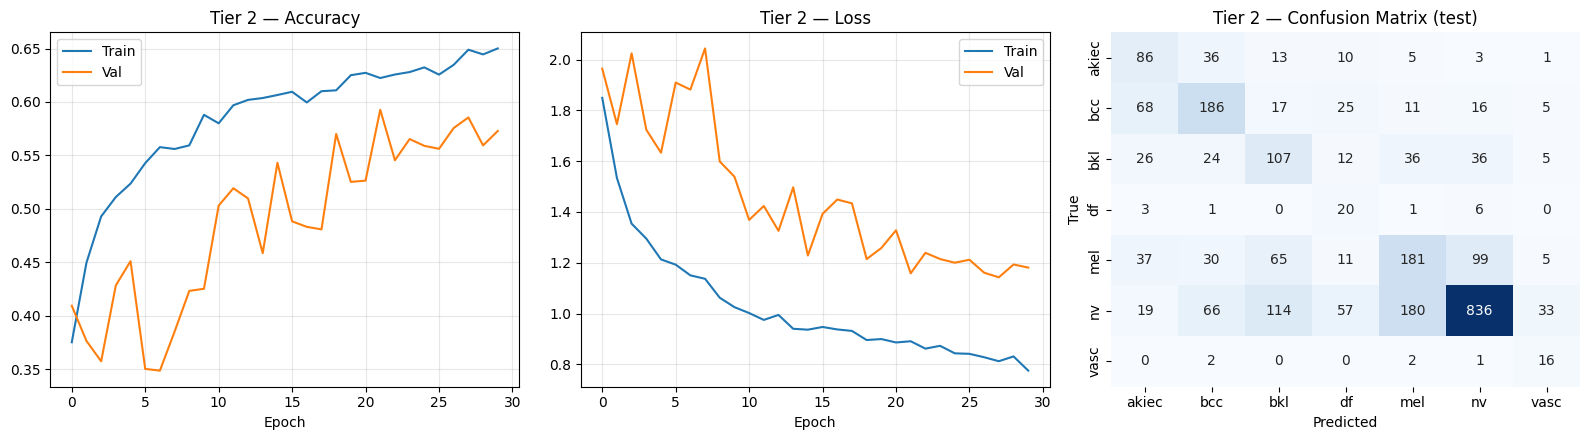


✓ Tier 2 done in 15.6 min
  Test accuracy: 56.98%

######################################################################
# TIER 3
#   Output: /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier3
#   Train samples: 14,061
#   LR=0.001, batch=32, epochs=30
######################################################################
  Steps per epoch: 438
  Total params:       56,179,943
  Trainable params:    1,840,647  (BN-uri din bază înghețate)
  Paper Table 4:       1,840,647  (cu BN trainable)
Epoch 1/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.3287 - loss: 1.8873
Epoch 1: val_accuracy improved from None to 0.33783, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier3/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier3/best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 86s 126ms/step - accuracy: 0.3828 - loss: 1.7965 - val_accuracy: 0.3378 - val_loss: 2.1247 - learning_rate: 0.0010
Epoch 2/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.4306 - loss: 1.4374
Epoch 2: val_accuracy improved from 0.33783 to 0.40929, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier3/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier3/best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 38s 88ms/step - accuracy: 0.4494 - loss: 1.4687 - val_accuracy: 0.4093 - val_loss: 1.7319 - learning_rate: 0.0010
Epoch 3/30
437/438 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.4698 - loss: 1.2878
Epoch 3: val_accuracy did not improve from 0.40929
438/438 ━━━━━━━━━━━━━━━━━━━━ 35s 81ms/step - accuracy: 0.4862 - loss: 1.3532 - val_accuracy: 0.38

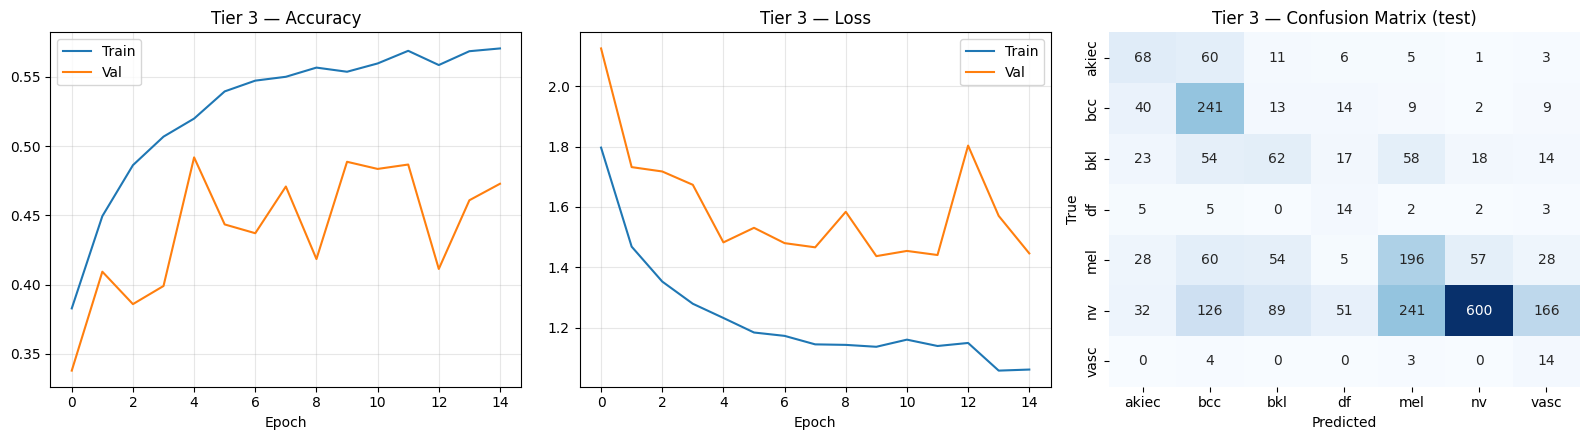


✓ Tier 3 done in 10.3 min
  Test accuracy: 47.55%

######################################################################
# TIER 4
#   Output: /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier4
#   Train samples: 17,300
#   LR=0.001, batch=32, epochs=30
######################################################################
  Steps per epoch: 539
  Total params:       56,179,943
  Trainable params:    1,840,647  (BN-uri din bază înghețate)
  Paper Table 4:       1,840,647  (cu BN trainable)
Epoch 1/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.3513 - loss: 1.8388
Epoch 1: val_accuracy improved from None to 0.40492, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier4/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier4/best.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 93s 115ms/step - accuracy: 0.4029 - loss: 1.7421 - val_accuracy: 0.4049 - val_loss: 1.7096 - learning_rate: 0.0010
Epoch 2/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.4584 - loss: 1.4471
Epoch 2: val_accuracy improved from 0.40492 to 0.45891, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier4/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier4/best.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 43s 80ms/step - accuracy: 0.4654 - loss: 1.5013 - val_accuracy: 0.4589 - val_loss: 1.5518 - learning_rate: 0.0010
Epoch 3/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.4907 - loss: 1.3155
Epoch 3: val_accuracy did not improve from 0.45891
539/539 ━━━━━━━━━━━━━━━━━━━━ 42s 78ms/step - accuracy: 0.4975 - loss: 1.3656 - val_accuracy: 0.44

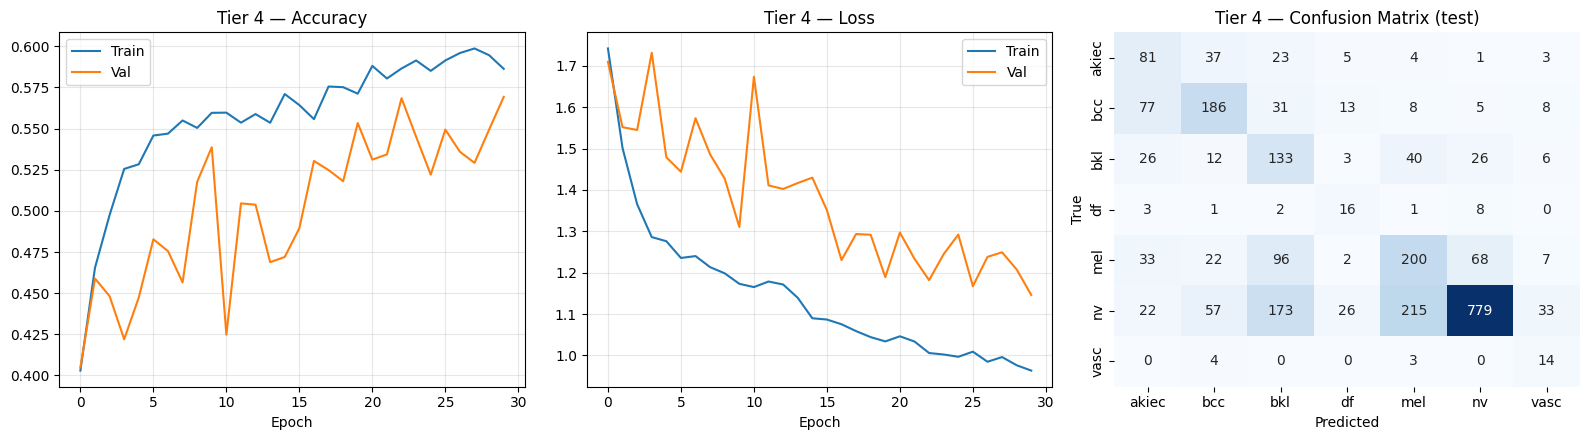


✓ Tier 4 done in 22.7 min
  Test accuracy: 56.07%

######################################################################
# TIER 5
#   Output: /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier5
#   Train samples: 20,299
#   LR=0.001, batch=32, epochs=30
######################################################################
  Steps per epoch: 633
  Total params:       56,179,943
  Trainable params:    1,840,647  (BN-uri din bază înghețate)
  Paper Table 4:       1,840,647  (cu BN trainable)
Epoch 1/30
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.3628 - loss: 1.8098
Epoch 1: val_accuracy improved from None to 0.43112, saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier5/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/tier5/best.keras
633/633 ━━━━━━━━━━━━━━━━━━━━ 99s 108ms/step - accuracy: 0.4023 - loss: 1.7491 - val_accuracy: 0.4311 - val_loss: 1.6050 - learning_rate: 0.0010
Epoch 2/30
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.4756 - loss: 1.3756
Epoch 2: val_accuracy did not improve from 0.43112
633/633 ━━━━━━━━━━━━━━━━━━━━ 47s 74ms/step - accuracy: 0.4838 - loss: 1.4686 - val_accuracy: 0.3351 - val_loss: 1.8242 - learning_rate: 0.0010
Epoch 3/30
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.5028 - loss: 1.1941
Epoch 3: val_accuracy did not improve from 0.43112
633/633 ━━━━━━━━━━━━━━━━━━━━ 46s 73ms/step - accuracy: 0.5103 - loss: 1.3335 - val_accuracy: 0.4057 - val_loss: 1.6155 - learning_rate: 0.0010
Epoch 4/30
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.5160 - loss: 1.2415
Epoch 4: val_accuracy did not improve from 0.43112

Epoch 4: ReduceLROnPlateau reducing l

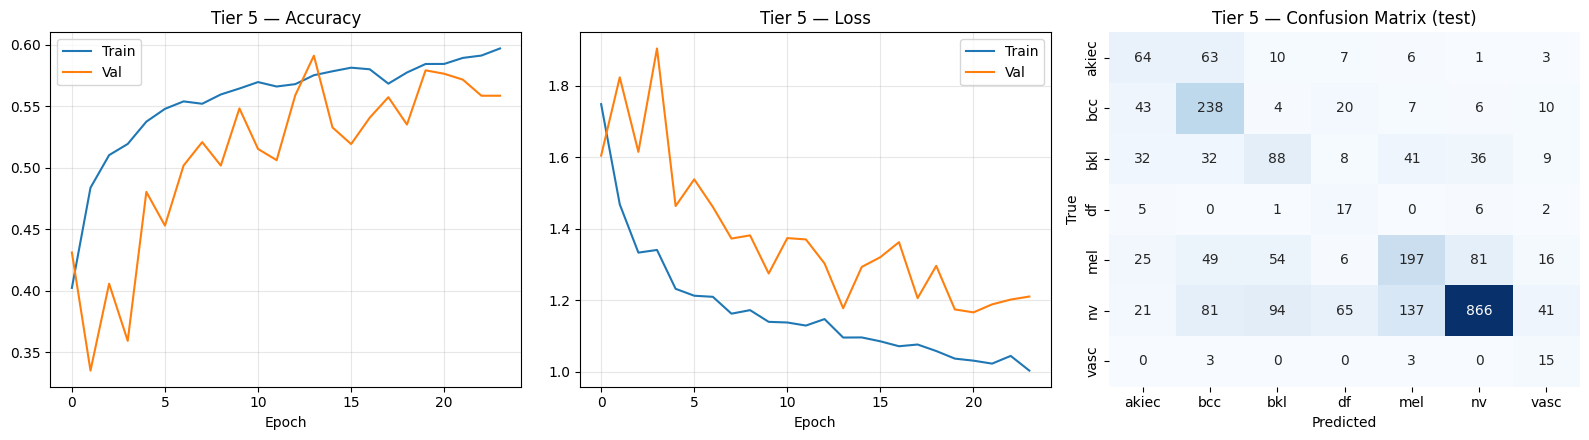


✓ Tier 5 done in 21.0 min
  Test accuracy: 59.09%

ALL TIERS COMPLETE


In [30]:
all_results = {}

for tier in TIERS_TO_RUN:
    all_results[tier] = train_tier(tier)

print('\n' + '=' * 70)
print('ALL TIERS COMPLETE')
print('=' * 70)

## 6. Summary

In [32]:
# ─── Tabel sumar ───
rows = []
for tier, res in sorted(all_results.items()):
    rows.append({
        'tier': tier,
        'train_samples': res['train_samples'],
        'epochs': res['epochs_run'],
        'val_acc': res['val']['accuracy'] * 100,
        'val_macro_f1': res['val']['macro_f1'],
        'test_acc': res['test']['accuracy'] * 100,
        'test_macro_f1': res['test']['macro_f1'],
        'test_weighted_f1': res['test']['weighted_f1'],
        'test_auc': res['test']['auc'],
        'time_min': res['time_minutes'],
    })

summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

summary_df.to_csv(OUTPUT_DIR / 'summary.csv', index=False)
print(f'\nSummary saved to: {OUTPUT_DIR / "summary.csv"}')

 tier  train_samples  epochs  val_acc  val_macro_f1  test_acc  test_macro_f1  test_weighted_f1  test_auc  time_min
    1           8042      22   48.591         0.386    46.956          0.333             0.508     0.806     9.652
    2          10996      30   59.270         0.460    56.984          0.448             0.593     0.850    15.574
    3          14061      15   49.186         0.378    47.553          0.362             0.509     0.837    10.344
    4          17300      30   56.927         0.457    56.068          0.451             0.589     0.859    22.685
    5          20299      24   59.111         0.435    59.093          0.434             0.613     0.860    20.953

Summary saved to: /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive/summary.csv


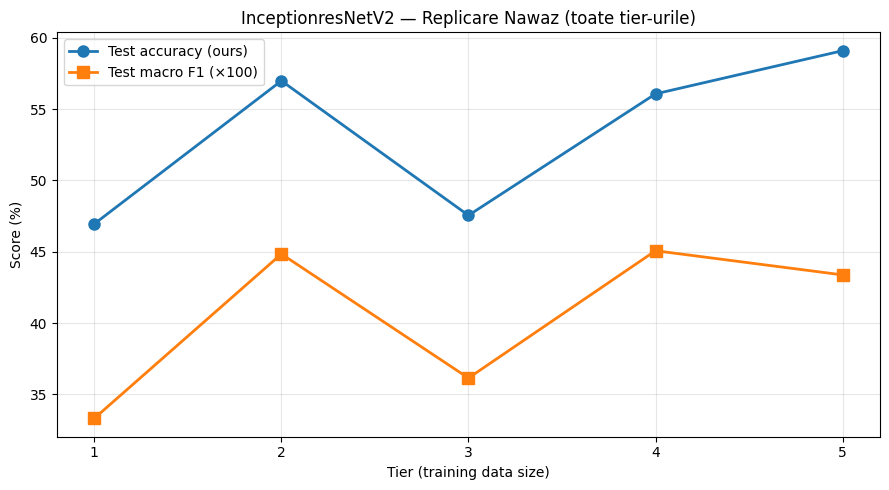

In [33]:
# ─── Test accuracy vs tier (cu paper baseline) ───
fig, ax = plt.subplots(figsize=(9, 5))

tiers_x = [r['tier'] for r in rows]
test_acc = [r['test_acc'] for r in rows]
macro_f1 = [r['test_macro_f1'] * 100 for r in rows]

ax.plot(tiers_x, test_acc, 'o-', label='Test accuracy (ours)', linewidth=2, markersize=8)
ax.plot(tiers_x, macro_f1, 's-', label='Test macro F1 (×100)', linewidth=2, markersize=8)
ax.set_xlabel('Tier (training data size)')
ax.set_ylabel('Score (%)')
ax.set_title('InceptionresNetV2 — Replicare Nawaz (toate tier-urile)')
ax.set_xticks(tiers_x)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'tiers_summary.png', dpi=120, bbox_inches='tight')
plt.show()

In [34]:
# ─── Classification report per tier (test set) ───
for tier in sorted(all_results.keys()):
    print(f'\n{"="*70}\nTier {tier} — TEST classification report\n{"="*70}')
    print(all_results[tier]['test']['classification_report'])


Tier 1 — TEST classification report
              precision    recall  f1-score   support

       akiec       0.28      0.19      0.23       154
         bcc       0.51      0.22      0.31       328
         bkl       0.20      0.57      0.30       246
          df       0.08      0.48      0.14        31
         mel       0.35      0.40      0.37       428
          nv       0.87      0.57      0.69      1305
        vasc       0.24      0.43      0.31        21

    accuracy                           0.47      2513
   macro avg       0.36      0.41      0.33      2513
weighted avg       0.62      0.47      0.51      2513


Tier 2 — TEST classification report
              precision    recall  f1-score   support

       akiec       0.36      0.56      0.44       154
         bcc       0.54      0.57      0.55       328
         bkl       0.34      0.43      0.38       246
          df       0.15      0.65      0.24        31
         mel       0.44      0.42      0.43       428
    